# Price elasticity of online retail demand

**Question.** How responsive is weekly demand to the average price paid for a product, and how certain are we about it?

**Data.** Kaggle `thedevastator/online-retail-transaction-data` (license listed as "other"; read 2026-11-17).
The rows are invoice-line sales from a UK-based online gift retailer, Dec 2010 to Dec 2011.
Raw data is not committed. See `data/README.md`.

**Model.** Within-product log-log regression with week effects, HC3 standard errors, and a 95% CI.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from dp_elasticity.data import load_transactions, weekly_panel
from dp_elasticity.model import (
    estimate_elasticity,
    fit_elasticity,
    naive_elasticity,
    segment_elasticities,
)

RAW = Path("../data/raw/online_retail.csv")
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

## 1. Load and clean

In [2]:
raw = pd.read_csv(RAW, encoding="latin1", dtype={"InvoiceNo": str, "StockCode": str})
tx = load_transactions(RAW)

quality = pd.Series(
    {
        "raw lines": len(raw),
        "cancellation invoices (C*)": int(raw["InvoiceNo"].str.startswith("C").sum()),
        "quantity <= 0": int((raw["Quantity"] <= 0).sum()),
        "unit price <= 0": int((raw["UnitPrice"] <= 0).sum()),
        "lines kept": len(tx),
        "lines without CustomerID (kept)": int(tx["CustomerID"].isna().sum()),
    }
)
quality

raw lines                          541909
cancellation invoices (C*)           9288
quantity <= 0                       10624
unit price <= 0                      2517
lines kept                         530104
lines without CustomerID (kept)    132220
dtype: int64

## 2. Product-week panel

Products sold in at least 30 distinct weeks are kept. Price is revenue divided by units in each week.

In [3]:
panel = weekly_panel(tx, min_weeks=30)
print(f"products: {panel['StockCode'].nunique()}, product-weeks: {len(panel)}")
print(f"weeks covered: {panel['week'].nunique()}")
panel[["StockCode", "week", "quantity", "price"]].head()

products: 1639, product-weeks: 71960
weeks covered: 53


,StockCode,week,quantity,price
0,10125,2010-11-29,2,0.850000
1,10125,2010-12-06,43,0.887674
2,10125,2010-12-13,102,0.444314
3,10125,2010-12-20,7,0.810000
4,10125,2011-01-03,98,0.491633


## 3. Naive versus within-product estimate

A pooled regression mixes cheap high-volume products with expensive low-volume ones, which pulls the slope toward zero.
The within-product estimate removes product level differences.

In [4]:
naive = naive_elasticity(panel)
main = estimate_elasticity(panel)
pd.DataFrame(
    {
        "specification": ["pooled OLS (no product effects)", "product + week effects (main)"],
        "elasticity": [naive.elasticity, main.elasticity],
        "ci_low": [naive.ci_low, main.ci_low],
        "ci_high": [naive.ci_high, main.ci_high],
        "observations": [naive.n_obs, main.n_obs],
    }
)

,specification,elasticity,ci_low,ci_high,observations
0,pooled OLS (no product effects),-0.585314,-0.595563,-0.575065,71960
1,product + week effects (main),-2.047701,-2.097093,-1.998309,71960


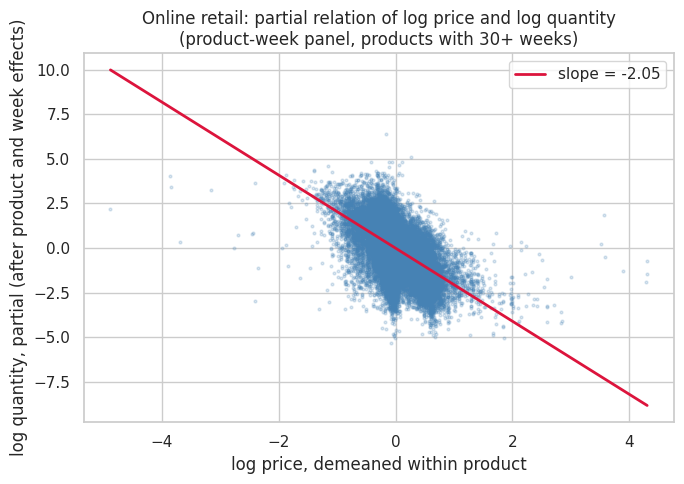

In [5]:
fit = fit_elasticity(panel)
x_within = fit.model.exog[:, fit.model.exog_names.index("log_p")]
partial_y = fit.resid + main.elasticity * x_within

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x_within, partial_y, s=4, alpha=0.2, color="steelblue")
xs = np.linspace(x_within.min(), x_within.max(), 100)
ax.plot(xs, main.elasticity * xs, color="crimson", lw=2, label=f"slope = {main.elasticity:.2f}")
ax.set_xlabel("log price, demeaned within product")
ax.set_ylabel("log quantity, partial (after product and week effects)")
ax.set_title("Online retail: partial relation of log price and log quantity\n(product-week panel, products with 30+ weeks)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "within_product_scatter.png", dpi=150)
plt.show()

## 4. Main estimate and interval

The 95% CI excludes −1, so demand is elastic on average: a 1% price rise is associated with a larger percentage drop in quantity.

In [6]:
print(f"elasticity = {main.elasticity:.3f}, 95% CI [{main.ci_low:.3f}, {main.ci_high:.3f}]")
print(f"CI includes -1 (unit-elastic threshold): {main.ci_includes_minus_one}")
print(f"CI includes 0: {main.ci_includes_zero}")

elasticity = -2.048, 95% CI [-2.097, -1.998]
CI includes -1 (unit-elastic threshold): False
CI includes 0: False


## 5. Sensitivity

Two concerns drive the sensitivity checks.
1. **Minimum weeks per product.** Changing the threshold changes which products enter.
2. **Bulk orders.** Lines with 100+ units are about 1% of lines but about 21% of revenue. Wholesale buyers often pay lower unit prices, which can make the slope more negative for reasons unrelated to consumer response.

The table shows whether the conclusion depends on these choices.

In [7]:
rows = []
for min_weeks in [20, 30, 40]:
    res = estimate_elasticity(weekly_panel(tx, min_weeks=min_weeks))
    rows.append({"spec": f"min weeks = {min_weeks}", "elasticity": res.elasticity, "ci_low": res.ci_low, "ci_high": res.ci_high, "products": res.n_products})
for cap in [100, 24]:
    res = estimate_elasticity(weekly_panel(tx[tx["Quantity"] < cap], min_weeks=30))
    rows.append({"spec": f"lines with quantity < {cap}", "elasticity": res.elasticity, "ci_low": res.ci_low, "ci_high": res.ci_high, "products": res.n_products})
sens = pd.DataFrame(rows)
sens

,spec,elasticity,ci_low,ci_high,products
0,min weeks = 20,-1.993226,-2.032286,-1.954166,2259
1,min weeks = 30,-2.047701,-2.097093,-1.998309,1639
2,min weeks = 40,-2.166112,-2.244759,-2.087464,1098
3,lines with quantity < 100,-1.894441,-1.940248,-1.848634,1631
4,lines with quantity < 24,-1.418545,-1.459923,-1.377166,1543


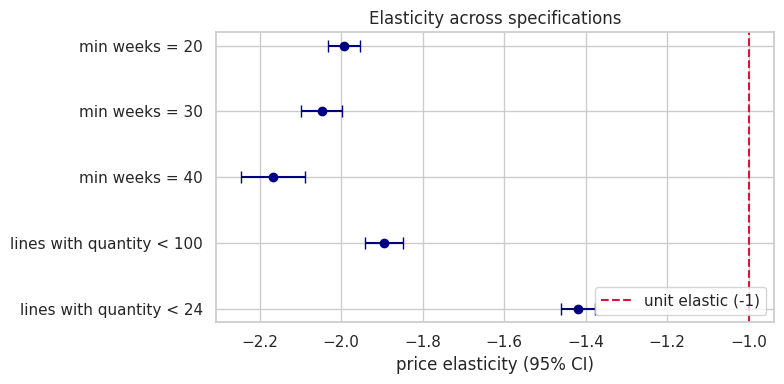

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
y = np.arange(len(sens))
ax.errorbar(
    sens["elasticity"], y,
    xerr=[sens["elasticity"] - sens["ci_low"], sens["ci_high"] - sens["elasticity"]],
    fmt="o", color="navy", capsize=4,
)
ax.axvline(-1, color="crimson", ls="--", label="unit elastic (-1)")
ax.set_yticks(y, sens["spec"])
ax.invert_yaxis()
ax.set_xlabel("price elasticity (95% CI)")
ax.set_title("Elasticity across specifications")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "sensitivity_forest.png", dpi=150)
plt.show()

## 6. Diagnostics

Residuals should centre on zero without strong structure against the fitted values.

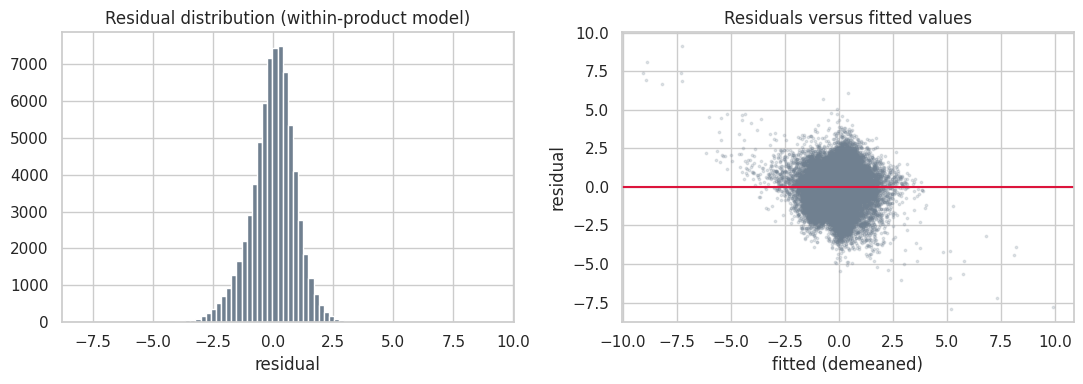

residual mean: -3.70e-20, residual sd: 0.944


In [9]:
resid = fit.resid
fitted = fit.fittedvalues
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(resid, bins=80, color="slategray")
axes[0].set_title("Residual distribution (within-product model)")
axes[0].set_xlabel("residual")
axes[1].scatter(fitted, resid, s=3, alpha=0.2, color="slategray")
axes[1].axhline(0, color="crimson")
axes[1].set_title("Residuals versus fitted values")
axes[1].set_xlabel("fitted (demeaned)")
axes[1].set_ylabel("residual")
fig.tight_layout()
fig.savefig(FIG / "residual_diagnostics.png", dpi=150)
plt.show()
print(f"residual mean: {resid.mean():.2e}, residual sd: {resid.std():.3f}")

## 7. Elasticity by price tier

Tiers are quartiles of each product's mean log price. A tier is reported only if it has at least 50 products.

In [10]:
seg = segment_elasticities(panel)
seg

,tier,elasticity,ci_low,ci_high,n_products,n_obs
0,0,-1.943123,-1.998655,-1.887590,410,17991
1,1,-2.142845,-2.201855,-2.083835,410,17892
2,2,-2.511679,-2.579000,-2.444359,409,18044
3,3,-1.672698,-1.843015,-1.502381,410,18033


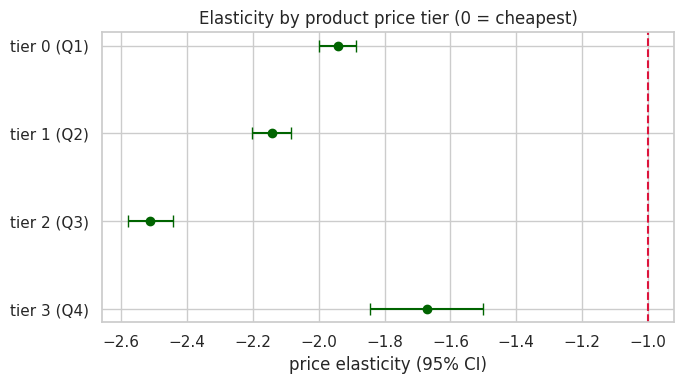

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(
    seg["elasticity"], seg["tier"],
    xerr=[seg["elasticity"] - seg["ci_low"], seg["ci_high"] - seg["elasticity"]],
    fmt="o", color="darkgreen", capsize=4,
)
ax.axvline(-1, color="crimson", ls="--")
ax.set_yticks(seg["tier"], [f"tier {t} (Q{t + 1})" for t in seg["tier"]])
ax.invert_yaxis()
ax.set_xlabel("price elasticity (95% CI)")
ax.set_title("Elasticity by product price tier (0 = cheapest)")
fig.tight_layout()
fig.savefig(FIG / "elasticity_by_tier.png", dpi=150)
plt.show()

## 8. Summary

- Within-product elasticity is about **−2.0** on all lines, and about **−1.4** on retail-sized lines (quantity < 24).
  Both intervals exclude −1, so demand is elastic in both specifications. The magnitude depends on the sample.
- The pooled estimate (about −0.6) is biased toward zero by cross-product differences.
- The estimate is not a causal price effect. Prices are set by the retailer and react to demand, and promotions coincide with demand spikes.
  Week effects remove common seasonality only. The result should be read as an association, and it is conditional on this sample.

In [12]:
summary = pd.DataFrame(
    {
        "estimate": ["naive pooled", "within-product, all lines", "within-product, quantity < 24"],
        "elasticity": [naive.elasticity, main.elasticity, sens.iloc[4]["elasticity"]],
    }
)
summary

,estimate,elasticity
0,naive pooled,-0.585314
1,"within-product, all lines",-2.047701
2,"within-product, quantity < 24",-1.418545
